In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
from matplotlib.patches import Patch

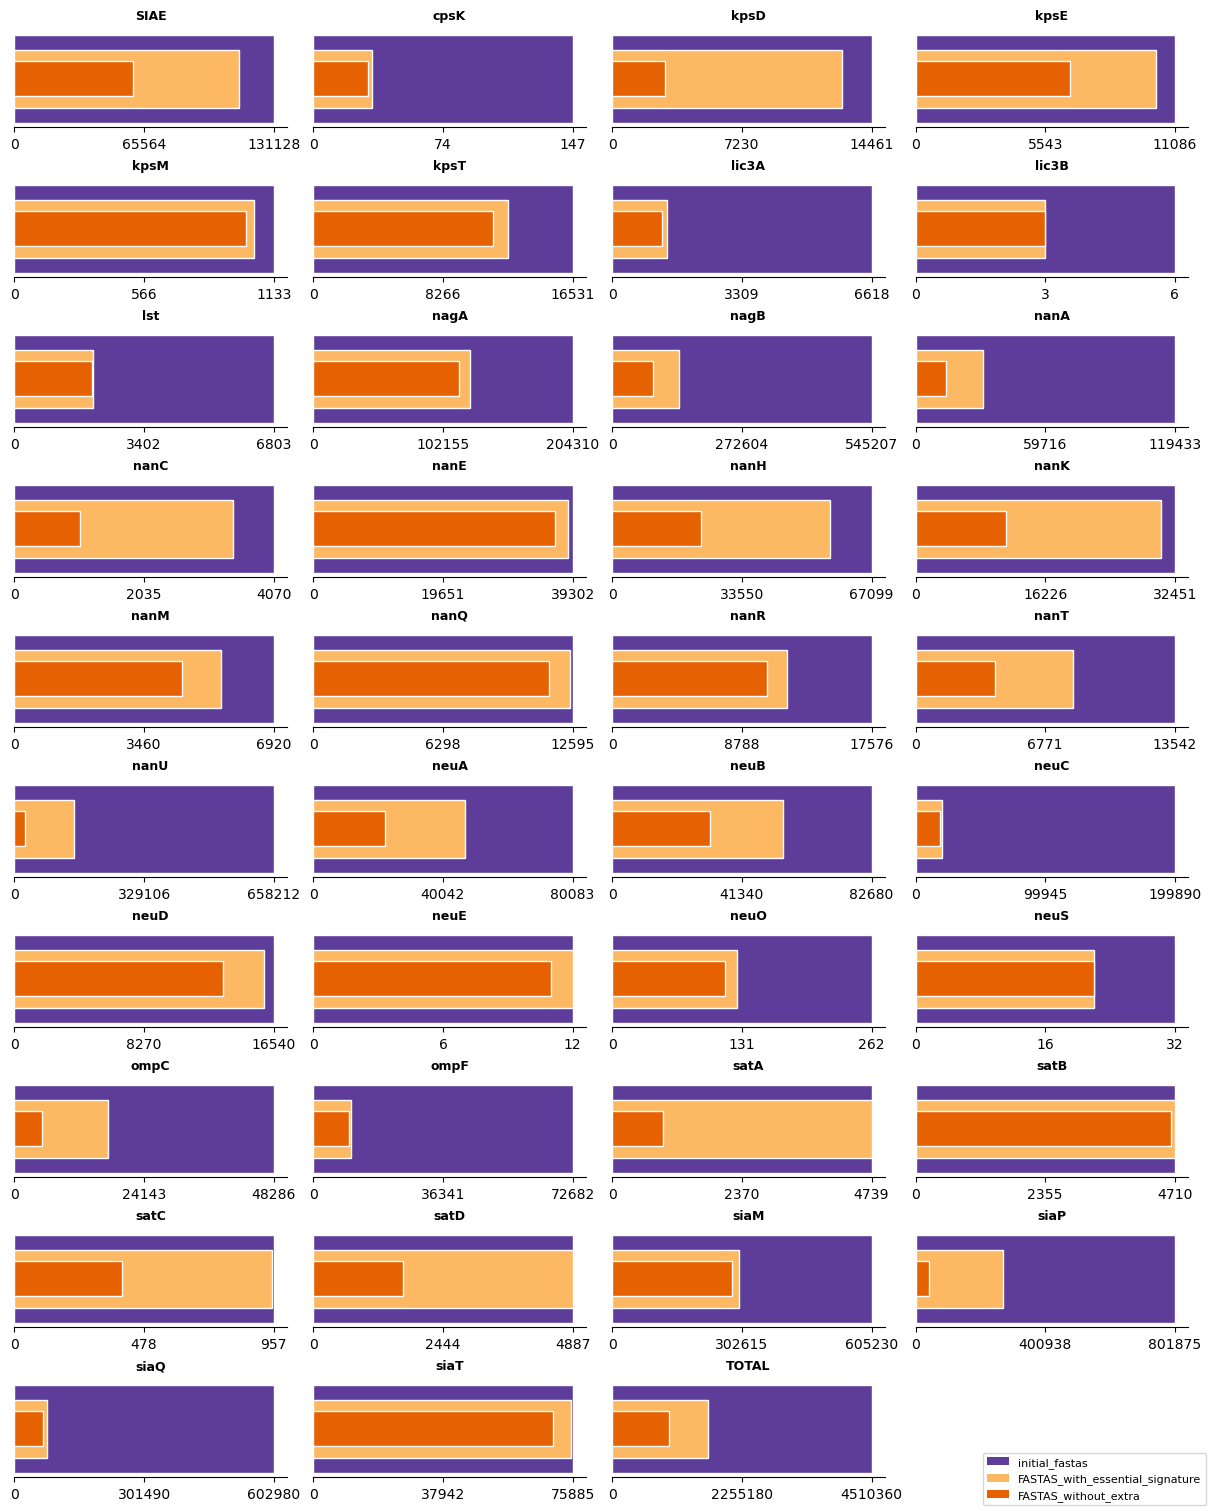

In [10]:
# === 1. Ler o CSV já resumido ===
df = pd.read_csv("/media/Data/thais/sialic_acid_catalog/banco_de_dados/redo_all/final_fastas/final_fastas_summary.csv")

# Garantir que as colunas existem e são numéricas
expected = ["gene", "initial_fastas", "FASTAS_with_essential_signature", "FASTAS_without_extra"]
for c in expected:
    if c not in df.columns:
        raise ValueError(f"Coluna faltando no CSV: {c}")

df[["initial_fastas", "FASTAS_with_essential_signature", "FASTAS_without_extra"]] = (
    df[["initial_fastas", "FASTAS_with_essential_signature", "FASTAS_without_extra"]]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# === Preparar grid de gráficos ===
n = len(df)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(ncols * 3, nrows * 1.5),
    constrained_layout=True
)
axes = axes.flatten()

# === Cores ===
cores = {
    "initial_fastas": "#5e3c99",
    "FASTAS_with_essential_signature": "#fdb863",
    "FASTAS_without_extra": "#e66101",
}

# === Gerar gráficos: barras "aninhadas" ===
for i, row in df.iterrows():
    gene = row["gene"]
    total = float(row["initial_fastas"])
    essencial = float(row["FASTAS_with_essential_signature"])
    sem_extra = float(row["FASTAS_without_extra"])

    # Barra base = total
    axes[i].barh(0, total, height=0.30, color=cores["initial_fastas"], label="initial_fastas", zorder=1, edgecolor='white')

    # Barra menor por cima = subset com assinatura essencial
    # alinhada à esquerda (left=0)
    axes[i].barh(0, essencial, height=0.20, color=cores["FASTAS_with_essential_signature"],
                 label="FASTAS_with_essential_signature", zorder=2, edgecolor='white')

    # Barra ainda menor = subset dentro da essencial que não tem assinaturas extras
    axes[i].barh(0, sem_extra, height=0.12, color=cores["FASTAS_without_extra"],
                 label="FASTAS_without_extra", zorder=3, edgecolor='white')
    # Ajustes do eixo
    axes[i].set_yticks([])
    axes[i].set_title(gene, fontsize=9, fontweight="bold", pad=8)

    # xticks com base no total (evita erro se total == 0)
    max_tick = max(total, 1)
    axes[i].set_xticks([0, max_tick / 2, max_tick])
    axes[i].set_xticklabels([0, f"{max_tick/2:.0f}", f"{max_tick:.0f}"])
    for spine in ("top", "right", "left"):
        axes[i].spines[spine].set_visible(False)

# Remover eixos extras, se houver
last_plotted = i  # i do loop
for j in range(last_plotted + 1, len(axes)):
    fig.delaxes(axes[j])

# === Legenda geral (usando patches para evitar rótulos duplicados) ===
legend_elements = [
    Patch(facecolor=cores["initial_fastas"], label="initial_fastas"),
    Patch(facecolor=cores["FASTAS_with_essential_signature"], label="FASTAS_with_essential_signature"),
    Patch(facecolor=cores["FASTAS_without_extra"], label="FASTAS_without_extra"),
]
fig.legend(handles=legend_elements, loc="lower right", fontsize=8)

plt.show()